<>:156: SyntaxWarning: invalid escape sequence '\D'
<>:156: SyntaxWarning: invalid escape sequence '\D'
/tmp/ipykernel_709/3338552499.py:156: SyntaxWarning: invalid escape sequence '\D'
  plt.ylabel('Log-Likelihood Inflation ($\Delta LL$) [log scale]', fontsize=12)


Starting H5 Macro Simulation: Automated P-Hacking via Stepwise Selection...
True Causal Effect (beta) = 0.05, Spurious Noise Pool Size = 50

--- Running for N = 1,000 ---
  Delta LL (True)       = 0.76
  Delta LL (Best Noise) = 5.84 (MCSE: 0.5982)
  FWER (P-Hacked Rate)  = 100.0%

--- Running for N = 10,000 ---
  Delta LL (True)       = 1.20
  Delta LL (Best Noise) = 26.79 (MCSE: 1.8902)
  FWER (P-Hacked Rate)  = 100.0%

--- Running for N = 100,000 ---
  Delta LL (True)       = 7.38
  Delta LL (Best Noise) = 203.39 (MCSE: 8.1645)
  FWER (P-Hacked Rate)  = 100.0%

--- Running for N = 1,000,000 ---
  Delta LL (True)       = 83.43
  Delta LL (Best Noise) = 1957.24 (MCSE: 94.4769)
  FWER (P-Hacked Rate)  = 100.0%

--- Running for N = 5,000,000 ---
  Delta LL (True)       = 406.15
  Delta LL (Best Noise) = 9756.60 (MCSE: 389.2699)
  FWER (P-Hacked Rate)  = 100.0%

--- Running for N = 10,000,000 ---
  Delta LL (True)       = 792.10
  Delta LL (Best Noise) = 18670.55 (MCSE: 694.8800)
  FWER (

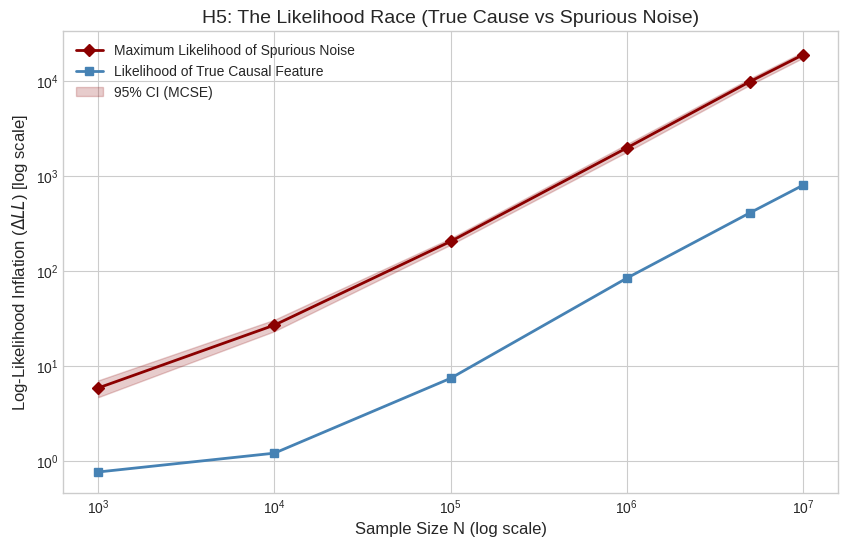

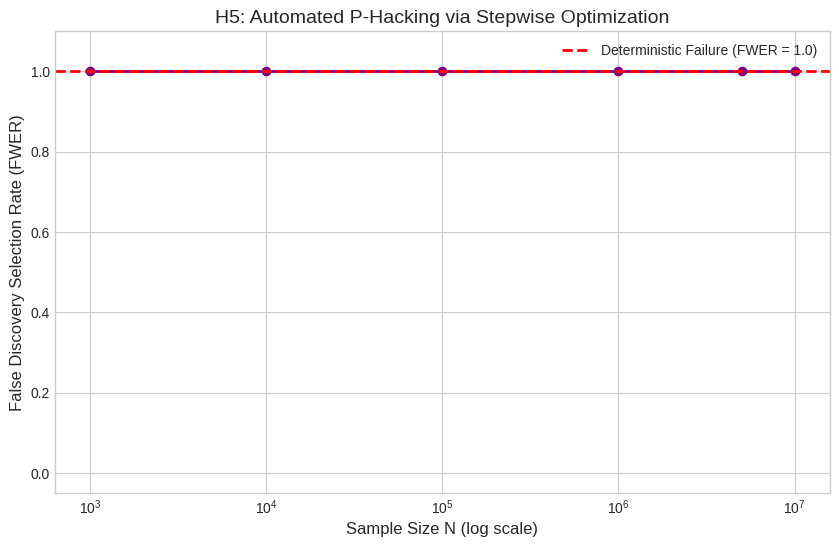

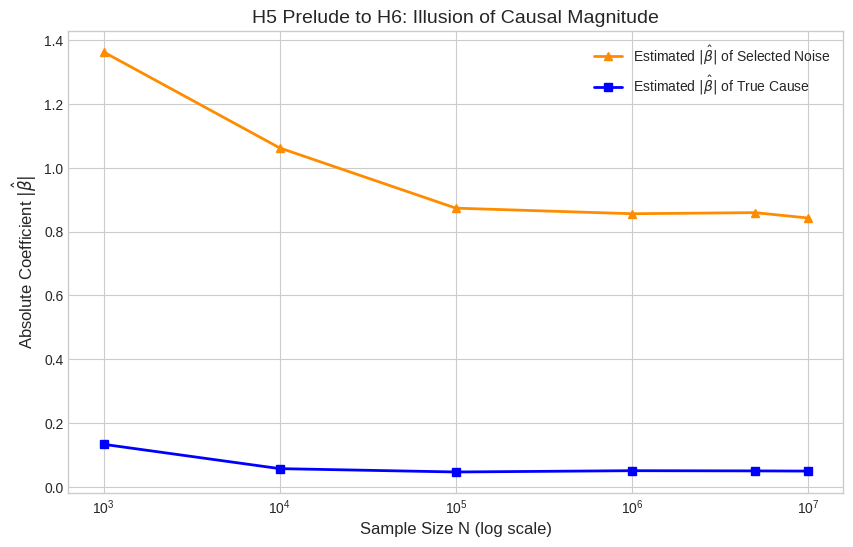


All calculations completed successfully. Generating H5_Simulation_Results.zip...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import log_loss
import warnings
import os
import zipfile
import gc
from google.colab import files

# ==========================================
# H5: Automated P-Hacking via Stepwise Selection
# ==========================================
warnings.filterwarnings("ignore")

output_dir = "h5_simulation_results"
os.makedirs(output_dir, exist_ok=True)

# シミュレーション設定
N_list = [1000, 10000, 100000, 1000000, 5000000, 10000000]
D = 50  # 探索プール内のノイズ変数の数
T = 10  # MCSE用試行回数

# 真の因果関係の設定（穏やかだが確実に存在する主効果）
beta_true = 0.05

# 認知ノイズ空間の設定（極端な偏りと微小な測定バイアス）
bias_max = 0.02  # 最大2%の微小な疑似相関（測定上のアーティファクト）

results_summary = []

print("Starting H5 Macro Simulation: Automated P-Hacking via Stepwise Selection...")
print(f"True Causal Effect (beta) = {beta_true}, Spurious Noise Pool Size = {D}")

for N in N_list:
    print(f"\n--- Running for N = {N:,} ---")
    trial_results = []

    for t in range(T):
        # 1. 真の因果関係を持つデータの生成
        X_true = np.random.binomial(1, 0.5, N).astype(np.int8)
        # 真の因果関係に基づく目的変数の生成 (Sigmoid関数)
        prob_y = 1 / (1 + np.exp(-(beta_true * (X_true - 0.5))))
        y = np.random.binomial(1, prob_y).astype(np.int8)

        # Nullモデルの尤度
        p_null = np.mean(y)
        ll_null = -N * log_loss(y, np.full(N, p_null))

        # 2. 真の因果変数の評価
        clf_true = LogisticRegression(penalty=None, solver='lbfgs')
        clf_true.fit(X_true.reshape(-1, 1), y)
        ll_true = -N * log_loss(y, clf_true.predict_proba(X_true.reshape(-1, 1)))
        delta_ll_true = ll_true - ll_null
        beta_est_true = np.abs(clf_true.coef_[0][0])

        del X_true

        # 3. ノイズプールの探索（ステップワイズ法の1ステップ目をシミュレート）
        # DGP: 初期値依存性を排除し、毎試行ランダムな偏りと微小バイアスを生成
        p_base = np.random.uniform(0.01, 0.05, D)  # 強い偏り（1%〜5%の出現率）
        delta_bias = np.random.uniform(0.0, bias_max, D) # 0〜2%の微小な測定バイアス

        max_delta_ll_noise = -np.inf
        best_beta_noise = 0

        # メモリ節約のため、1変数ずつ生成・評価して破棄する
        for j in range(D):
            prob_x = np.clip(p_base[j] + delta_bias[j] * y, 0, 1)
            x_noise = np.random.binomial(1, prob_x).astype(np.int8)

            clf_noise = LogisticRegression(penalty=None, solver='lbfgs')
            clf_noise.fit(x_noise.reshape(-1, 1), y)
            ll_noise = -N * log_loss(y, clf_noise.predict_proba(x_noise.reshape(-1, 1)))

            delta_ll_noise = ll_noise - ll_null
            beta_noise = np.abs(clf_noise.coef_[0][0])

            # 最も尤度をブーストする「最悪のノイズ」を記憶
            if delta_ll_noise > max_delta_ll_noise:
                max_delta_ll_noise = delta_ll_noise
                best_beta_noise = beta_noise

            del x_noise

        gc.collect()

        # 4. ステップワイズ選択の勝敗判定
        # パラメータ数は同じ(k=1)であるため、Delta LLが大きい方がAIC/BICでも必ず選択される
        is_phacked = 1 if max_delta_ll_noise > delta_ll_true else 0

        trial_results.append({
            'Trial': t + 1,
            'N': N,
            'Delta_LL_True': delta_ll_true,
            'Delta_LL_Best_Noise': max_delta_ll_noise,
            'Beta_True_Est': beta_est_true,
            'Beta_Best_Noise_Est': best_beta_noise,
            'Is_PHacked': is_phacked
        })

    # DataFrame化して保存
    df_trials = pd.DataFrame(trial_results)
    df_trials.to_csv(f"{output_dir}/h5_trials_N_{N}.csv", index=False)

    # 統計量の計算
    mean_ll_true = df_trials['Delta_LL_True'].mean()
    mean_ll_noise = df_trials['Delta_LL_Best_Noise'].mean()
    mcse_ll_noise = df_trials['Delta_LL_Best_Noise'].std() / np.sqrt(T)

    mean_beta_true = df_trials['Beta_True_Est'].mean()
    mean_beta_noise = df_trials['Beta_Best_Noise_Est'].mean()

    # FWER (False Discovery Selection Rate)
    selection_error_rate = df_trials['Is_PHacked'].mean()

    print(f"  Delta LL (True)       = {mean_ll_true:.2f}")
    print(f"  Delta LL (Best Noise) = {mean_ll_noise:.2f} (MCSE: {mcse_ll_noise:.4f})")
    print(f"  FWER (P-Hacked Rate)  = {selection_error_rate * 100:.1f}%")

    results_summary.append({
        'Sample_Size_N': N,
        'Mean_Delta_LL_True': mean_ll_true,
        'Mean_Delta_LL_Best_Noise': mean_ll_noise,
        'MCSE_Delta_LL_Best_Noise': mcse_ll_noise,
        'Mean_Beta_True_Est': mean_beta_true,
        'Mean_Beta_Best_Noise_Est': mean_beta_noise,
        'Selection_Error_Rate_FWER': selection_error_rate
    })

df_summary = pd.DataFrame(results_summary)
df_summary.to_csv(f"{output_dir}/h5_summary_metrics.csv", index=False)

# ==========================================
# グラフの描画と保存
# ==========================================
plt.style.use('seaborn-v0_8-whitegrid')

# 1. 尤度の競争：本物の因果関係 vs 最強のノイズ
plt.figure(figsize=(10, 6))
plt.plot(df_summary['Sample_Size_N'], df_summary['Mean_Delta_LL_Best_Noise'],
         marker='D', color='darkred', linewidth=2, label='Maximum Likelihood of Spurious Noise')
plt.plot(df_summary['Sample_Size_N'], df_summary['Mean_Delta_LL_True'],
         marker='s', color='steelblue', linewidth=2, label='Likelihood of True Causal Feature')

plt.fill_between(df_summary['Sample_Size_N'],
                 df_summary['Mean_Delta_LL_Best_Noise'] - 1.96 * df_summary['MCSE_Delta_LL_Best_Noise'],
                 df_summary['Mean_Delta_LL_Best_Noise'] + 1.96 * df_summary['MCSE_Delta_LL_Best_Noise'],
                 color='darkred', alpha=0.2, label='95% CI (MCSE)')

plt.xscale('log')
plt.yscale('log')
plt.xlabel('Sample Size N (log scale)', fontsize=12)
plt.ylabel('Log-Likelihood Inflation ($\Delta LL$) [log scale]', fontsize=12)
plt.title('H5: The Likelihood Race (True Cause vs Spurious Noise)', fontsize=14)
plt.legend(fontsize=10)
plt.savefig(f"{output_dir}/fig1_likelihood_race.png", dpi=300, bbox_inches='tight')
plt.show()

# 2. 自動P値ハッキング率 (FWER) の推移
plt.figure(figsize=(10, 6))
plt.plot(df_summary['Sample_Size_N'], df_summary['Selection_Error_Rate_FWER'],
         marker='o', color='purple', linewidth=2)
plt.axhline(y=1.0, color='red', linestyle='--', linewidth=2, label='Deterministic Failure (FWER = 1.0)')

plt.xscale('log')
plt.ylim(-0.05, 1.1)
plt.xlabel('Sample Size N (log scale)', fontsize=12)
plt.ylabel('False Discovery Selection Rate (FWER)', fontsize=12)
plt.title('H5: Automated P-Hacking via Stepwise Optimization', fontsize=14)
plt.legend(fontsize=10)
plt.savefig(f"{output_dir}/fig2_automated_phacking_fwer.png", dpi=300, bbox_inches='tight')
plt.show()

# 3. H6への伏線：係数の巨大化比較
plt.figure(figsize=(10, 6))
plt.plot(df_summary['Sample_Size_N'], df_summary['Mean_Beta_Best_Noise_Est'],
         marker='^', color='darkorange', linewidth=2, label=r'Estimated $|\hat{\beta}|$ of Selected Noise')
plt.plot(df_summary['Sample_Size_N'], df_summary['Mean_Beta_True_Est'],
         marker='s', color='blue', linewidth=2, label=r'Estimated $|\hat{\beta}|$ of True Cause')

plt.xscale('log')
plt.xlabel('Sample Size N (log scale)', fontsize=12)
plt.ylabel(r'Absolute Coefficient $|\hat{\beta}|$', fontsize=12)
plt.title('H5 Prelude to H6: Illusion of Causal Magnitude', fontsize=14)
plt.legend(fontsize=10)
plt.savefig(f"{output_dir}/fig3_coefficient_illusion.png", dpi=300, bbox_inches='tight')
plt.show()

# ZIP圧縮
zip_filename = "H5_Simulation_Results.zip"
with zipfile.ZipFile(zip_filename, 'w') as zipf:
    for root, dirs, files_list in os.walk(output_dir):
        for file in files_list:
            zipf.write(os.path.join(root, file), arcname=file)

print(f"\nAll calculations completed successfully. Generating {zip_filename}...")
files.download(zip_filename)